# Rapalog Discovery Pipeline
## 05 Docking pipeline notebook
### **Phase 5: Docking Binding Affinity (using AutoDoc Vina)** 
A. Lock candidate selection
B. Extract rapamycin binding site (from PDB file)
C. Validate rapamycin docking box (numerical + visual)
D. Prepare sampled candidate ligands
E. Prepare FKBP12 protein receptor
F. Run docking
G. Analyze results

## How to run this notebook
### Configuration scenarios in <code>config.py</code>
| Scenario | Key flags | What it does |
|---|---|---|
| First-time build | `DOCKING_RUN_MODE="production"`, `DOCKING_USE_RANDOM_TEST_SET=False`, `DOCKING_LOCK_FINAL_TEST_SET=False`, `DOCKING_RECOMPUTE_LIGANDS=True`, `DOCKING_SKIP_RUN=False` | Builds production candidate and ligand caches, then runs docking. |
| Cache reuse | `DOCKING_RUN_MODE="production"`, `DOCKING_USE_RANDOM_TEST_SET=False`, `DOCKING_LOCK_FINAL_TEST_SET=True`, `DOCKING_RECOMPUTE_LIGANDS=False`, `DOCKING_SKIP_RUN=False` | Loads cached candidates and ligands and avoids rebuilding them. |
| Reproducible rerun | `DOCKING_RUN_MODE="production"`, `DOCKING_USE_RANDOM_TEST_SET=False`, `DOCKING_LOCK_FINAL_TEST_SET=True`, `DOCKING_RECOMPUTE_LIGANDS=False`, `DOCKING_SKIP_RUN=False` | Reuses fixed candidates and ligand cache for stable reruns. |
| Debug / iteration | `DOCKING_RUN_MODE="debug"`, `DOCKING_LOCK_FINAL_TEST_SET=False`, `DOCKING_RECOMPUTE_LIGANDS=True`, `DOCKING_SKIP_RUN=True` | Runs a reduced workflow for faster iteration. |

### Parameters used directly in this notebook
| Parameter | Used for |
|---|---|
| `DOCKING_N_SAMPLES_TOTAL` | Total candidate target for Cell 3 stratified selection. |
| `DOCKING_RUN_MODE` | Select debug/production mode and mode-specific cache filenames. |
| `DOCKING_SIMILARITY_COL` | Similarity column used to rank and stratify candidates. |
| `DOCKING_USE_RANDOM_TEST_SET` | Apply random-sampling override after candidate selection. |
| `DOCKING_RANDOM_TEST_SET_SIZE` | Number of rows sampled when random test set is enabled. |
| `DOCKING_LOCK_FINAL_TEST_SET` | Reuse cached candidate set or rebuild it. |
| `DOCKING_RECOMPUTE_LIGANDS` | Rebuild ligand PDBQT cache or load it if present. |
| `DOCKING_LIGAND_PREP_PROGRESS_EVERY` | Progress-print interval during ligand preparation. |
| `DOCKING_SKIP_RUN` | Skip docking run and rely on checkpoint if available. |
| `DOCKING_PDB_FILE` | Input receptor PDB filename in `data/raw`. |
| `DOCKING_CLEAN_PDB_FILE` | Cleaned receptor PDB output filename. |
| `DOCKING_RECEPTOR_PDBQT_FILE` | Receptor PDBQT filename used by Vina. |
| `DOCKING_CANDIDATES_FILE_DEBUG`, `DOCKING_CANDIDATES_FILE_PRODUCTION` | Mode-specific candidate cache filenames. |
| `DOCKING_LIGANDS_PICKLE_FILE_DEBUG`, `DOCKING_LIGANDS_PICKLE_FILE_PRODUCTION` | Mode-specific ligand PDBQT cache filenames. |
| `DOCKING_CHECKPOINT_FILE_DEBUG`, `DOCKING_CHECKPOINT_FILE_PRODUCTION` | Mode-specific docking checkpoint filenames. |
| `DOCKING_BOX_PADDING` | Padding around rapamycin coordinates for inferred docking box. |
| `DOCKING_FIXED_BOX_SIZE` | Vina docking box size used in docking runs. |
| `DOCKING_EXHAUSTIVENESS` | Vina search thoroughness. |
| `DOCKING_NUM_POSES` | Number of binding poses requested from Vina. |
| `DOCKING_CHECKPOINT_EVERY` | Checkpoint frequency during docking loop. |
| `DOCKING_OBABEL_PATH` | Open Babel executable used for ligand/receptor conversion. |
| `DOCKING_REMOVE_HETATM_RESNAMES` | HETATM residue names removed during receptor preparation. |

In [7]:
# P5 setup: imports, paths, and docking module wiring
import sys
import pickle
import importlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import config
config = importlib.reload(config)

import src.docking as docking
import src.feature_engineering as feature_engineering
import src.clustering as clustering

docking = importlib.reload(docking)
feature_engineering = importlib.reload(feature_engineering)
clustering = importlib.reload(clustering)

from src.feature_engineering import build_feature_df
from src.clustering import run_kmeans
from src.docking import (
    define_binding_box,
    prepare_ligand_pdbqt,
    prepare_receptor,
    run_vina,
    analyze_docking_results,
)

run_mode = str(getattr(config, "DOCKING_RUN_MODE", "debug")).strip().lower()
if run_mode not in {"debug", "production"}:
    raise ValueError("DOCKING_RUN_MODE must be 'debug' or 'production'.")

mode_suffix = "debug" if run_mode == "debug" else "prod"
results_dir = PROJECT_ROOT / "results" / "notebook_05" / mode_suffix
raw_dir = PROJECT_ROOT / "data" / "raw"
processed_dir = PROJECT_ROOT / "data" / "processed"
results_dir.mkdir(parents=True, exist_ok=True)
processed_dir.mkdir(parents=True, exist_ok=True)

if run_mode == "debug":
    docking_candidates_file = getattr(config, "DOCKING_CANDIDATES_FILE_DEBUG", config.DOCKING_CANDIDATES_FILE)
    ligands_pickle_file = getattr(config, "DOCKING_LIGANDS_PICKLE_FILE_DEBUG", config.DOCKING_LIGANDS_PICKLE_FILE)
    checkpoint_file_name = getattr(config, "DOCKING_CHECKPOINT_FILE_DEBUG", config.DOCKING_CHECKPOINT_FILE)
else:
    docking_candidates_file = getattr(config, "DOCKING_CANDIDATES_FILE_PRODUCTION", config.DOCKING_CANDIDATES_FILE)
    ligands_pickle_file = getattr(config, "DOCKING_LIGANDS_PICKLE_FILE_PRODUCTION", config.DOCKING_LIGANDS_PICKLE_FILE)
    checkpoint_file_name = getattr(config, "DOCKING_CHECKPOINT_FILE_PRODUCTION", config.DOCKING_CHECKPOINT_FILE)

docking_candidates_path = processed_dir / docking_candidates_file
ligands_pickle_path = processed_dir / ligands_pickle_file
checkpoint_path = processed_dir / checkpoint_file_name

# Explicitly anchor the receptor PDB to data/raw.
pdb_input_path = raw_dir / config.DOCKING_PDB_FILE

print("Project root:", PROJECT_ROOT)
print("Run mode:", run_mode)
print("Results dir:", results_dir)
print("Processed dir:", processed_dir)
print("PDB input path:", pdb_input_path)
print("Candidates cache:", docking_candidates_path)
print("Ligands cache:", ligands_pickle_path)
print("Checkpoint file:", checkpoint_path)
print("DOCKING_N_SAMPLES_TOTAL:", config.DOCKING_N_SAMPLES_TOTAL)

Project root: /Users/alangale/Projects/rapalog-discovery-pipeline
Run mode: debug
Results dir: /Users/alangale/Projects/rapalog-discovery-pipeline/results/notebook_05/debug
Processed dir: /Users/alangale/Projects/rapalog-discovery-pipeline/data/processed
PDB input path: /Users/alangale/Projects/rapalog-discovery-pipeline/data/raw/1FKB.pdb
Candidates cache: /Users/alangale/Projects/rapalog-discovery-pipeline/data/processed/docking_candidates_debug.pkl
Ligands cache: /Users/alangale/Projects/rapalog-discovery-pipeline/data/processed/ligand_pdbqt_data_debug.pkl
Checkpoint file: /Users/alangale/Projects/rapalog-discovery-pipeline/data/processed/docking_checkpoint_debug.pkl
DOCKING_N_SAMPLES_TOTAL: 100


In [8]:
# P5.A Lock candidate selection
similarity_cache_path = raw_dir / config.SIMILARITY_SCORES_CACHE_FILE
if not similarity_cache_path.exists():
    raise FileNotFoundError(f"Missing similarity cache: {similarity_cache_path}")

with open(similarity_cache_path, "rb") as f:
    cached_scores = pickle.load(f)

results_df = cached_scores if isinstance(cached_scores, pd.DataFrame) else pd.DataFrame(cached_scores)
results_df = results_df.drop_duplicates(subset=["smiles"]).copy()
if "name" in results_df.columns and "coconut_id" in results_df.columns:
    results_df["name"] = results_df["name"].fillna(results_df["coconut_id"])

results_ranked = results_df.sort_values(by="sim_tv_frag", ascending=False).reset_index(drop=True).copy()
feat_all = build_feature_df(results_ranked, target_col=config.DOCKING_SIMILARITY_COL)
feature_cols = ["hbd", "hba", "rings", "aromatic_rings", "tpsa", "logp", "mw", "amide"]

plot_df = feat_all[["name", "smiles"] + feature_cols + [config.DOCKING_SIMILARITY_COL]].dropna().copy()
X_features = plot_df[feature_cols]
X_scaled = StandardScaler().fit_transform(X_features)
plot_df["cluster_k2"] = run_kmeans(X_scaled, 2, random_state=config.RANDOM_STATE)
plot_df["cluster_k4"] = run_kmeans(X_scaled, 4, random_state=config.RANDOM_STATE)

# If lock mode is enabled but cache does not exist yet, fall back to building it once.
load_locked_set = config.DOCKING_LOCK_FINAL_TEST_SET and docking_candidates_path.exists()
if config.DOCKING_LOCK_FINAL_TEST_SET and not docking_candidates_path.exists():
    print(
        f"Lock enabled but {docking_candidates_path.name} is missing. "
        "Building candidates now and saving for future locked runs."
    )

if (not load_locked_set) and (not config.DOCKING_USE_RANDOM_TEST_SET):
    docking_df = plot_df.copy().drop(columns=["cluster_k4"])
    docking_df = docking_df.sort_values(by=config.DOCKING_SIMILARITY_COL, ascending=False).reset_index(drop=True)

    docking_df_C0 = docking_df[docking_df["cluster_k2"] == 0].copy()
    docking_df_C1 = docking_df[docking_df["cluster_k2"] == 1].copy()

    ratio_C0 = len(docking_df_C0) / len(docking_df)
    ratio_C1 = len(docking_df_C1) / len(docking_df)

    n_samples_C0_per_q = max(1, int(round((config.DOCKING_N_SAMPLES_TOTAL * ratio_C0) / 4.0)))
    n_samples_C1_per_q = max(1, int(round((config.DOCKING_N_SAMPLES_TOTAL * ratio_C1) / 4.0)))

    docking_df_C0["quartile"] = pd.qcut(
        docking_df_C0[config.DOCKING_SIMILARITY_COL], q=4, labels=[3, 2, 1, 0], duplicates="drop"
    )
    docking_df_C1["quartile"] = pd.qcut(
        docking_df_C1[config.DOCKING_SIMILARITY_COL], q=4, labels=[3, 2, 1, 0], duplicates="drop"
    )

    c0_group_sizes = docking_df_C0.groupby("quartile").size()
    c1_group_sizes = docking_df_C1.groupby("quartile").size()
    n0 = min(n_samples_C0_per_q, int(c0_group_sizes.min())) if len(c0_group_sizes) else 0
    n1 = min(n_samples_C1_per_q, int(c1_group_sizes.min())) if len(c1_group_sizes) else 0

    sample_C0 = docking_df_C0.groupby("quartile", group_keys=False).sample(n=n0, random_state=config.RANDOM_STATE)
    sample_C1 = docking_df_C1.groupby("quartile", group_keys=False).sample(n=n1, random_state=config.RANDOM_STATE)

    docking_candidates_df = pd.concat([sample_C0, sample_C1]).reset_index(drop=True)

    with open(docking_candidates_path, "wb") as f:
        pickle.dump(docking_candidates_df, f, protocol=pickle.HIGHEST_PROTOCOL)

    print(f"C0 samples: {len(sample_C0)} ({n0} per quartile)")
    print(f"C1 samples: {len(sample_C1)} ({n1} per quartile)")
    print(f"Total docking candidates: {len(docking_candidates_df)}")

else:
    with open(docking_candidates_path, "rb") as f:
        docking_candidates_df = pickle.load(f)
    print(f"Loaded {len(docking_candidates_df)} docking candidates from {docking_candidates_path.name}")

if config.DOCKING_USE_RANDOM_TEST_SET:
    n_sample = min(config.DOCKING_RANDOM_TEST_SET_SIZE, len(docking_candidates_df))
    docking_candidates_df = docking_candidates_df.sample(
        n=n_sample,
        random_state=config.RANDOM_STATE,
    ).reset_index(drop=True)
    print(f"Using random test set: {n_sample} rows")

print("Selected for docking:", len(docking_candidates_df))
display(docking_candidates_df.head())

[20:40:36] WARNING: not removing hydrogen atom without neighbors


Lock enabled but docking_candidates_debug.pkl is missing. Building candidates now and saving for future locked runs.
C0 samples: 60 (15 per quartile)
C1 samples: 40 (10 per quartile)
Total docking candidates: 100
Selected for docking: 100


/var/folders/_l/vlm5pys14pq7q19wh7lzcbf40000gn/T/ipykernel_42410/3711673080.py:52: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  c0_group_sizes = docking_df_C0.groupby("quartile").size()
/var/folders/_l/vlm5pys14pq7q19wh7lzcbf40000gn/T/ipykernel_42410/3711673080.py:53: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  c1_group_sizes = docking_df_C1.groupby("quartile").size()
/var/folders/_l/vlm5pys14pq7q19wh7lzcbf40000gn/T/ipykernel_42410/3711673080.py:57: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current beh

,name,smiles,hbd,hba,rings,aromatic_rings,tpsa,logp,mw,amide,sim_r1_tv_frag,cluster_k2,quartile
0,3-[4-(4-methoxyphenoxy)pyrimidin-2-yl]-N-[(3-m...,COC1=CC=C(OC2=CC=NC(C3=CC=CC(C(=O)NCC4=CC=CC(O...,1,6,4,4,82.57,4.88310,441.487,1,0.208333,0,3
1,CNP0177360.0,COC1=CC=C(CC2=COC3=C(C=O)C(O)=C(C)C(OC)=C3C2=O...,1,6,3,3,85.97,3.22752,354.358,0,0.142857,0,3
2,CNP0271681.4,C[C@H]1CCC=C2C[C@H]3OC(=O)[C@@H](CN4CCC(O)(C5=...,2,5,5,1,70.00,3.90840,460.014,0,0.210970,0,3
3,STL579223,CCCCC1=CC(=O)OC2=C(CN3C[C@H]4C[C@@H](C3)C3=CC=...,1,5,5,3,75.68,3.62220,420.509,0,0.162602,0,3
4,"2-(3,4-dimethoxyphenyl)-5,7-diisopropyl-1,3-di...",COC1=CC=C([C@H]2N3C[C@@]4(C(C)C)C[N@]2C[C@@](C...,1,5,5,1,45.17,2.99290,374.525,0,0.172414,0,3


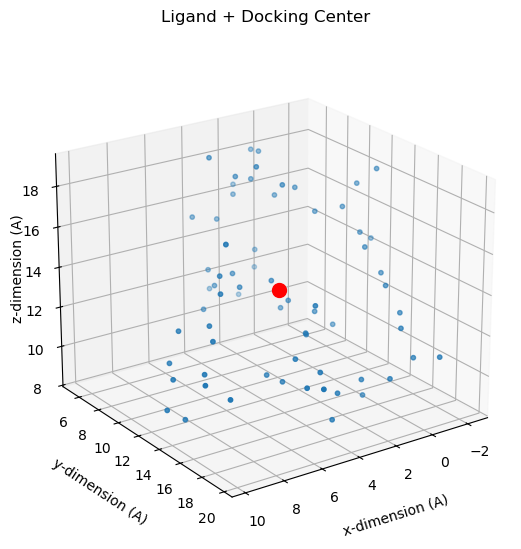

Center: [ 3.1993816 12.129957  13.313499 ]
Box size: [17.060001 19.328999 15.177   ]
Contains ligand min coords: True
Contains ligand max coords: True


In [3]:
# P5.B-P5.C Define and validate rapamycin docking box
binding_box = define_binding_box(
    pdb_file=pdb_input_path,
    ligand_resname="RAP",
    box_padding=config.DOCKING_BOX_PADDING,
    plot=True,
    plot_output_path=results_dir / "rapamycin_binding_box_validation.png",
)

center_coords = binding_box["center_coords"]
box_size_coords = binding_box["box_size_coords"]

print("Center:", center_coords)
print("Box size:", box_size_coords)
print("Contains ligand min coords:", binding_box["contains_min"])
print("Contains ligand max coords:", binding_box["contains_max"])

In [ ]:
# P5.D Prepare sampled candidate ligands
# Use an explicit recompute flag + explicit cache path.
RECOMPUTE_LIGANDS = bool(config.DOCKING_RECOMPUTE_LIGANDS)
LIGANDS_PICKLE_PATH = ligands_pickle_path

# Always prep ligands for exactly the candidates selected in Cell 3.
docking_candidates_for_ligands = docking_candidates_df.copy()

# If ligand cache is missing, force a one-time recompute so downstream cells can proceed.
recompute_ligands = RECOMPUTE_LIGANDS or (not LIGANDS_PICKLE_PATH.exists())
if (not RECOMPUTE_LIGANDS) and (not LIGANDS_PICKLE_PATH.exists()):
    print(
        f"Ligand cache missing at {LIGANDS_PICKLE_PATH.name}. "
        "Running one-time ligand PDBQT generation now."
    )

ligand_pdbqt_data, ligand_failures = prepare_ligand_pdbqt(
    docking_candidates_for_ligands,
    ligands_pickle_path=LIGANDS_PICKLE_PATH,
    recompute=recompute_ligands,
    random_seed=config.RANDOM_STATE,
)

# Enforce candidate/cache consistency: if cache contents do not match Cell 3 candidates, rebuild.
candidate_names = set(docking_candidates_for_ligands["name"].astype(str).tolist())
prepared_names = {str(name) for name, _ in ligand_pdbqt_data}
if (not recompute_ligands) and (prepared_names != candidate_names):
    print(
        "Ligand cache does not match current Cell 3 candidates; "
        "rebuilding ligand PDBQT data now."
    )
    ligand_pdbqt_data, ligand_failures = prepare_ligand_pdbqt(
        docking_candidates_for_ligands,
        ligands_pickle_path=LIGANDS_PICKLE_PATH,
        recompute=True,
        random_seed=config.RANDOM_STATE,
    )

# Recover from stale/empty cache produced by earlier failed generation attempts.
if len(ligand_pdbqt_data) == 0 and len(docking_candidates_for_ligands) > 0:
    print("Ligand cache is empty; rebuilding ligand PDBQT data now.")
    ligand_pdbqt_data, ligand_failures = prepare_ligand_pdbqt(
        docking_candidates_for_ligands,
        ligands_pickle_path=LIGANDS_PICKLE_PATH,
        recompute=True,
        random_seed=config.RANDOM_STATE,
    )

print(f"Candidates selected (Cell 3): {len(docking_candidates_for_ligands)}")
print(f"Ligands ready: {len(ligand_pdbqt_data)}")
print(f"Ligand failures: {len(ligand_failures)}")
print(f"Ligand cache path: {LIGANDS_PICKLE_PATH}")
if ligand_failures:
    display(pd.DataFrame(ligand_failures, columns=["name", "error"]).head())

Ligand prep speed mode: using 25 of 100 candidates (set DOCKING_LIGAND_PREP_MAX=None for full run).
Ligand cache missing at ligand_pdbqt_data_debug.pkl. Running one-time ligand PDBQT generation now.
Ligand prep progress: 5/25 | success=5 | failed=0
Ligand prep progress: 10/25 | success=10 | failed=0
Ligand prep progress: 15/25 | success=15 | failed=0
Ligand prep progress: 20/25 | success=20 | failed=0
Ligand prep progress: 25/25 | success=25 | failed=0
Ligands ready: 25
Ligand failures: 0
Ligand cache path: /Users/alangale/Projects/rapalog-discovery-pipeline/data/processed/ligand_pdbqt_data_debug.pkl


In [10]:
# Debug: inspect Meeko install paths in active notebook kernel
import os
import inspect
import meeko
from pathlib import Path
from meeko import MoleculePreparation

print("meeko version:", getattr(meeko, "__version__", "unknown"))
print("meeko file:", meeko.__file__)

meeko_dir = Path(meeko.__file__).resolve().parent
params_dir = meeko_dir / "data" / "params"
print("params dir:", params_dir)
print("params dir exists:", params_dir.exists())
if params_dir.exists():
    print("params files:", sorted([p.name for p in params_dir.glob("*.json")])[:20])

print("MoleculePreparation signature:", inspect.signature(MoleculePreparation))
if ligand_failures:
    print("First ligand error:", ligand_failures[0][1])

meeko version: 0.6.0
meeko file: /Users/alangale/miniconda3/envs/tfmac/lib/python3.10/site-packages/meeko/__init__.py
params dir: /Users/alangale/miniconda3/envs/tfmac/lib/python3.10/site-packages/meeko/data/params
params dir exists: False
MoleculePreparation signature: (merge_these_atom_types=('H',), hydrate=False, flexible_amides=False, rigid_macrocycles=False, min_ring_size=7, max_ring_size=33, keep_chorded_rings=False, keep_equivalent_rings=False, double_bond_penalty=50, macrocycle_allow_A=False, rigidify_bonds_smarts=[], rigidify_bonds_indices=[], input_atom_params=None, load_atom_params='ad4_types', add_atom_types=(), input_offatom_params=None, load_offatom_params=None, charge_model='gasteiger', dihedral_model=None, reactive_smarts=None, reactive_smarts_idx=None, add_index_map=False, remove_smiles=False)


In [11]:
# P5.E Prepare FKBP12 receptor PDBQT
receptor_info = prepare_receptor(
    input_pdb=pdb_input_path,
    clean_pdb=processed_dir / config.DOCKING_CLEAN_PDB_FILE,
    output_pdbqt=processed_dir / config.DOCKING_RECEPTOR_PDBQT_FILE,
    obabel_path=config.DOCKING_OBABEL_PATH,
    remove_resnames=config.DOCKING_REMOVE_HETATM_RESNAMES,
)

print("Cleaned PDB:", receptor_info["clean_pdb"])
print("Receptor PDBQT:", receptor_info["receptor_pdbqt"])
print("Removed HETATM count:", receptor_info["removed_hetatm_count"])
print("Validation first line:", receptor_info["validation_first_line"])

Cleaned PDB: /Users/alangale/Projects/rapalog-discovery-pipeline/data/processed/1FKB_clean.pdb
Receptor PDBQT: /Users/alangale/Projects/rapalog-discovery-pipeline/data/processed/fkbp12.pdbqt
Removed HETATM count: 201
Validation first line: REMARK  Name = /Users/alangale/Projects/rapalog-discovery-pipeline/data/processed/1FKB_clean.pdb


In [ ]:
# P5.F Run docking
if config.DOCKING_SKIP_RUN:
    if checkpoint_path.exists():
        print(f"Loading docking checkpoint from: {checkpoint_path}")
    else:
        print(f"Checkpoint not found at {checkpoint_path}; docking_output will be empty.")

docking_output = run_vina(
    ligand_pdbqt_data=ligand_pdbqt_data,
    center_coords=center_coords,
    receptor_pdbqt=processed_dir / config.DOCKING_RECEPTOR_PDBQT_FILE,
    checkpoint_file=checkpoint_path,
    skip_docking=config.DOCKING_SKIP_RUN,
    exhaustiveness=config.DOCKING_EXHAUSTIVENESS,
    n_poses=config.DOCKING_NUM_POSES,
    box_size=config.DOCKING_FIXED_BOX_SIZE,
    checkpoint_every=config.DOCKING_CHECKPOINT_EVERY,
)

print(f"Docking outputs: {len(docking_output)}")
print(f"Checkpoint path: {checkpoint_path}")

In [ ]:
# P5.G Analyze docking results
analysis = analyze_docking_results(
    docking_output=docking_output,
    docking_candidates_df=docking_candidates_for_ligands,
    results_csv_path=results_dir / "docking_results_full.csv",
)

docking_results_df = analysis["docking_results_df"]
docking_full_df = analysis["docking_full_df"]

print("Top docking rows:")
display(docking_results_df.head())
print("Merged shape:", docking_full_df.shape)
print("Duplicate candidate names:", analysis["candidate_duplicate_names"])
print("Results CSV:", results_dir / "docking_results_full.csv")
display(docking_full_df.head())